# Poisson 2D en Fortran — portage GPU sur Google Colab




In [14]:
# 1. Vérifions qu'un GPU NVIDIA est bien attribué
!nvidia-smi

Wed Nov  4 21:55:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [15]:
# A. Récupération du projets
!git clone https://github.com/abdous-jpg/poisson-2d-fortran-gpu

Cloning into 'poisson-2d-fortran-gpu'...
remote: Enumerating objects: 22, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 22 (delta 0), reused 22 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (22/22), 117.25 KiB | 7.82 MiB/s, done.


In [16]:
%cd /content/poisson-2d-fortran-gpu
!ls

/content/poisson-2d-fortran-gpu
colab_gpu.ipynb  performance		 poisson-2d-fortran-gpu  results
convergence	 performance_gpu	 precision.mod		 scripts
convergence_gpu  performance_gpu_simple  README.md		 solveur.mod
Makefile	 performance_simple	 resultats_gpu.zip	 src


## 3. Installation de  gfortran et le NVIDIA HPC SDK (compilateur `nvfortran`)

In [17]:
!apt-get install -y -qq gfortran > /dev/null
!curl -s https://developer.download.nvidia.com/hpc-sdk/ubuntu/DEB-GPG-KEY-NVIDIA-HPC-SDK | gpg --yes --dearmor -o /usr/share/keyrings/nvidia-hpcsdk-archive-keyring.gpg
!echo 'deb [signed-by=/usr/share/keyrings/nvidia-hpcsdk-archive-keyring.gpg] https://developer.download.nvidia.com/hpc-sdk/ubuntu/amd64 /' > /etc/apt/sources.list.d/nvhpc.list
!apt-get update -qq

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [6]:
import subprocess
paquet = subprocess.run("apt-cache search --names-only '^nvhpc-[0-9]+-[0-9]+$' | cut -d' ' -f1 | sort -V | tail -1",
                        shell=True, capture_output=True, text=True).stdout.strip()
print("Paquet installé :", paquet)
!apt-get install -y -qq $paquet > /dev/null

Paquet installé : nvhpc-26-9


In [7]:
import glob, os, re
dossiers = [d for d in glob.glob("/opt/nvidia/hpc_sdk/Linux_x86_64/*/compilers/bin") if re.search(r"/\d+\.\d+/", d)]
bindir = sorted(dossiers, key=lambda d: [int(x) for x in re.search(r"/(\d+)\.(\d+)/", d).groups()])[-1]
os.environ["PATH"] = bindir + ":" + os.environ["PATH"]
!nvfortran --version


nvfortran 26.9-0 64-bit target on x86-64 Linux -tp skylake-avx512 
NVIDIA Compilers and Tools
Copyright (c) 2026, NVIDIA CORPORATION & AFFILIATES.  All rights reserved.


## 4. Compilation  et vérification  sur GPU
Le test de convergence doit afficher **OK : ordre 2 retrouvé**

In [18]:
!mkdir -p results && make gpu_test

nvfortran -O3 -mp=gpu -Minfo=mp -cpp -DUSE_GPU -o convergence_gpu src/precision.F90 src/solveur.F90 src/convergence.F90
src/precision.F90:
src/solveur.F90:
jacobi:
     48, !$omp target teams distribute parallel do
         48, Generating "nvkernel_solveur_jacobi__F1L48_2" GPU kernel
     58, !$omp target teams distribute parallel do
         58, Generating "nvkernel_solveur_jacobi__F1L58_4" GPU kernel
     69, !$omp target teams distribute parallel do
         69, Generating "nvkernel_solveur_jacobi__F1L69_6" GPU kernel
src/convergence.F90:
./convergence_gpu
    n         h   iterations    erreur L2   ordre
   17 6.250E-02         1222    1.515E-03    0.00
   33 3.125E-02         4621    3.896E-04    1.96
   65 1.563E-02        17350    9.887E-05    1.98
  129 7.813E-03        64814    2.490E-05    1.99
OK : ordre 2 retrouve


In [19]:
!make gpu && make && make simple

nvfortran -O3 -mp=gpu -Minfo=mp -cpp -DUSE_GPU -o performance_gpu src/precision.F90 src/solveur.F90 src/performance.F90
src/precision.F90:
src/solveur.F90:
jacobi:
     48, !$omp target teams distribute parallel do
         48, Generating "nvkernel_solveur_jacobi__F1L48_2" GPU kernel
     58, !$omp target teams distribute parallel do
         58, Generating "nvkernel_solveur_jacobi__F1L58_4" GPU kernel
     69, !$omp target teams distribute parallel do
         69, Generating "nvkernel_solveur_jacobi__F1L69_6" GPU kernel
src/performance.F90:
nvfortran -O3 -mp=gpu -Minfo=mp -cpp -DUSE_GPU -DSINGLE -o performance_gpu_simple src/precision.F90 src/solveur.F90 src/performance.F90
src/precision.F90:
src/solveur.F90:
jacobi:
     48, !$omp target teams distribute parallel do
         48, Generating "nvkernel_solveur_jacobi__F1L48_2" GPU kernel
     58, !$omp target teams distribute parallel do
         58, Generating "nvkernel_solveur_jacobi__F1L58_4" GPU kernel
     69, !$omp target teams di

In [20]:
!NVCOMPILER_ACC_NOTIFY=1 ./performance_gpu 65 2 2>&1 | head -8

launch CUDA kernel file=/content/poisson-2d-fortran-gpu/src/solveur.F90 function=jacobi line=48 device=0 host-threadid=0 num_teams=0 thread_limit=0 kernelname=nvkernel_solveur_jacobi__F1L48_2_ grid=<<<34,1,1>>> block=<<<128,1,1>>> shmem=0b
launch CUDA kernel file=/content/poisson-2d-fortran-gpu/src/solveur.F90 function=jacobi line=58 device=0 host-threadid=0 num_teams=0 thread_limit=0 kernelname=nvkernel_solveur_jacobi__F1L58_4_ grid=<<<32,1,1>>> block=<<<128,1,1>>> shmem=0b
launch CUDA kernel file=/content/poisson-2d-fortran-gpu/src/solveur.F90 function=jacobi line=69 device=0 host-threadid=0 num_teams=0 thread_limit=0 kernelname=nvkernel_solveur_jacobi__F1L69_6_ grid=<<<32,1,1>>> block=<<<128,1,1>>> shmem=0b
launch CUDA kernel file=/content/poisson-2d-fortran-gpu/src/solveur.F90 function=jacobi line=58 device=0 host-threadid=0 num_teams=0 thread_limit=0 kernelname=nvkernel_solveur_jacobi__F1L58_4_ grid=<<<32,1,1>>> block=<<<128,1,1>>> shmem=0b
launch CUDA kernel file=/content/poisson

## 5. Mesures CPU vs GPU (sur 500 itérations)

In [21]:
import subprocess, pandas as pd
versions = [("CPU double, 2 threads", "./performance"), ("CPU simple, 2 threads", "./performance_simple"),
            ("GPU double", "./performance_gpu"), ("GPU simple", "./performance_gpu_simple")]
lignes = []
for nom, prog in versions:
    for n in [513, 1025, 2049, 4097]:
        sortie = subprocess.run(f"OMP_NUM_THREADS=2 {prog} {n} 500", shell=True, capture_output=True, text=True).stdout.strip()
        _, iters, ms, mpts, octets = sortie.split(",")
        lignes.append({"version": nom, "n": n, "ms_par_iteration": float(ms), "mpoints_par_s": float(mpts)})
        print(nom, n, ms.strip(), "ms/it")
res = pd.DataFrame(lignes)
res.to_csv("results/gpu.csv", index=False)
ref = res[res.version == "CPU double, 2 threads"].set_index("n").ms_par_iteration
res["acceleration_vs_cpu_double"] = res.apply(lambda r: ref[r.n] / r.ms_par_iteration, axis=1).round(1)
res.pivot(index="version", columns="n", values="acceleration_vs_cpu_double")

CPU double, 2 threads 513 1.8690 ms/it
CPU double, 2 threads 1025 7.6142 ms/it
CPU double, 2 threads 2049 38.3893 ms/it
CPU double, 2 threads 4097 138.8399 ms/it
CPU simple, 2 threads 513 1.7360 ms/it
CPU simple, 2 threads 1025 6.8423 ms/it
CPU simple, 2 threads 2049 31.2702 ms/it
CPU simple, 2 threads 4097 126.9321 ms/it
GPU double 513 0.6981 ms/it
GPU double 1025 0.7598 ms/it
GPU double 2049 1.4528 ms/it
GPU double 4097 4.7704 ms/it
GPU simple 513 0.3923 ms/it
GPU simple 1025 0.4751 ms/it
GPU simple 2049 0.8947 ms/it
GPU simple 4097 2.5591 ms/it


n,513,1025,2049,4097
version,,,,
"CPU double, 2 threads",1.0,1.0,1.0,1.0
"CPU simple, 2 threads",1.1,1.1,1.2,1.1
GPU double,2.7,10.0,26.4,29.1
GPU simple,4.8,16.0,42.9,54.3


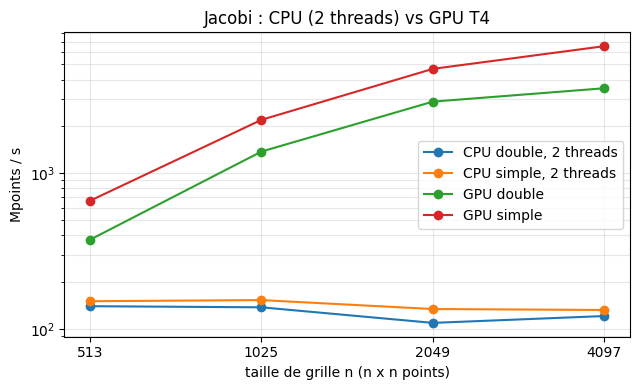

In [22]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.5, 4))
for nom, g in res.groupby("version"):
    ax.plot(g.n, g.mpoints_par_s, "o-", label=nom)
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xticks([513, 1025, 2049, 4097], ["513", "1025", "2049", "4097"])
ax.set_xlabel("taille de grille n (n x n points)"); ax.set_ylabel("Mpoints / s")
ax.set_title("Jacobi : CPU (2 threads) vs GPU T4"); ax.grid(True, which="both", alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig("results/gpu.png", dpi=150)